In [32]:
from pathlib import Path
import urllib.request
import pandas as pd

# 1. Define project/data paths
PROJECT_DIR = Path('..').resolve()
DATA_DIR = PROJECT_DIR / 'LAB 2' / 'data'
FILE_PATH = DATA_DIR / 'pima_diabetes.csv'
DATA_DIR.mkdir(parents=True, exist_ok=True)

# 3. Direct raw CSV URL
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'

# 4. Download and save the file
print(f'Downloading to: {FILE_PATH.resolve()}')
urllib.request.urlretrieve(url, FILE_PATH)

# 5. Load it with column names
columns = [
    'pregnancies', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label'
]

df = pd.read_csv(FILE_PATH, header = None, names=columns, sep=',')

print(df.head())
print(df.shape)






   pregnancies  glucose  bp  skin  insulin   bmi  pedigree  age  label
0            6      148  72    35        0  33.6     0.627   50      1
1            1       85  66    29        0  26.6     0.351   31      0
2            8      183  64     0        0  23.3     0.672   32      1
3            1       89  66    23       94  28.1     0.167   21      0
4            0      137  40    35      168  43.1     2.288   33      1
(768, 9)


In [33]:
#split the ds into features and targets
feature_cols = ['pregnancies', 'bmi', 'age', 'insulin', 'glucose', 'bp', 'pedigree' ]
X = df[feature_cols]
y = df.label


In [39]:
from sklearn.model_selection import train_test_split
 
# split X and y across training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=16)


In [ ]:
# import a logistic Regression model from Sklearn
from sklearn.linear_model import LogisticRegression 

logreg = LogisticRegression(random_state=16, max_iter=1000)

# train the model on our dataset and create a set of predicitions
logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_test)

In [51]:
from sklearn import metrics

cnf = metrics.confusion_matrix(y_test, y_pred)
cnf

array([[115,  10],
       [ 25,  42]])

Text(0.5, 427.9555555555555, 'predicted')

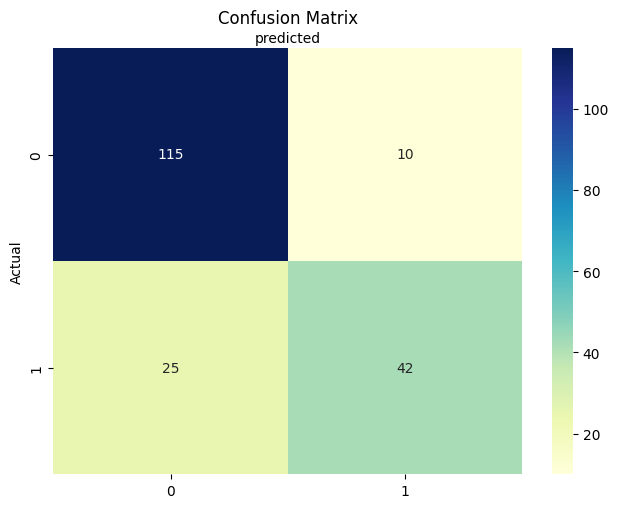

In [52]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class_names = [0,1]
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

sns.heatmap(pd.DataFrame(cnf), annot=True, cmap='YlGnBu', fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title("Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("predicted")



In [60]:
from sklearn.metrics import classification_report
target_names = ["Without diabetes", "With diabetes"]
print(classification_report(y_test, y_pred, target_names=target_names))


                  precision    recall  f1-score   support

Without diabetes       0.82      0.92      0.87       125
   With diabetes       0.81      0.63      0.71        67

        accuracy                           0.82       192
       macro avg       0.81      0.77      0.79       192
    weighted avg       0.82      0.82      0.81       192



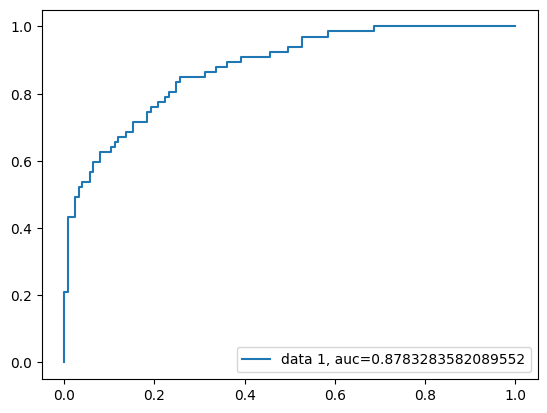

In [61]:
y_pred_proba = logreg.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr,tpr, label="data 1, auc="+str(auc))
plt.legend(loc=4)
plt.show()